<a href="https://colab.research.google.com/github/Aryanshh/CSET343/blob/main/Lab4_1758.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
# Load Breast Cancer Wisconsin Diagnostic dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="Outcome")

df = pd.concat([X, y], axis=1)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Outcome
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
print("Dataset Information:")
print(data.DESCR[:3000])

print("\nFeature Names:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(data.target_names)

Dataset Information:
.. _breast_cancer_dataset:

Breast cancer wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is 

In [4]:
# Mean, median, standard deviation, minimum, maximum, etc.
summary_stats = X.describe().T

summary_stats["median"] = X.median()

summary_stats = summary_stats[
    ["count", "mean", "median", "std", "min", "25%", "50%", "75%", "max"]
]

summary_stats

,count,mean,median,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,13.370000,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,18.840000,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,86.240000,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,551.100000,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.095870,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.092630,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.061540,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.033500,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.179200,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.061540,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [5]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values[missing_values > 0])

if missing_values.sum() == 0:
    print("\nNo missing values found.")

Missing Values:
Series([], dtype: int64)

No missing values found.


In [6]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates()
    print("Duplicates removed.")
else:
    print("No duplicate rows found.")

Number of duplicate rows: 0
No duplicate rows found.


In [7]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = ((X < lower_bound) | (X > upper_bound)).sum()

print("Outlier count for each feature:")
print(outlier_counts.sort_values(ascending=False))

Outlier count for each feature:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
worst symmetry             23
concavity error            22
texture error              20
concave points error       19
mean concavity             18
worst radius               17
worst compactness          16
mean compactness           16
mean symmetry              15
mean fractal dimension     15
worst perimeter            15
mean radius                14
mean perimeter             13
worst concavity            12
mean concave points        10
mean texture                7
worst smoothness            7
mean smoothness             6
worst texture               5
worst concave points        0
dtype: int64


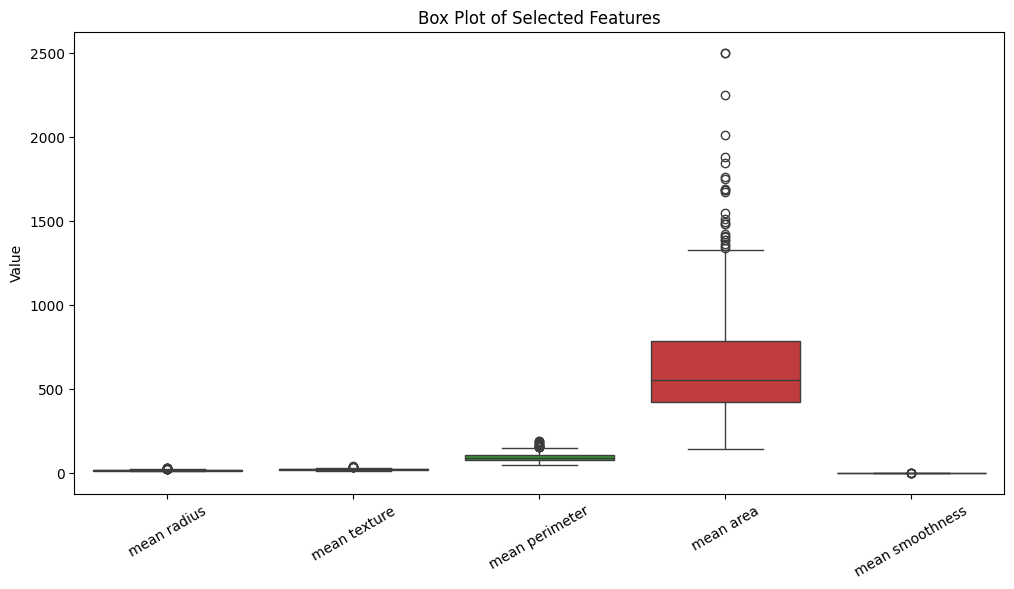

In [8]:
# Box plots for selected important features
selected_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness"
]

plt.figure(figsize=(12, 6))
sns.boxplot(data=X[selected_features])
plt.xticks(rotation=30)
plt.title("Box Plot of Selected Features")
plt.ylabel("Value")
plt.show()

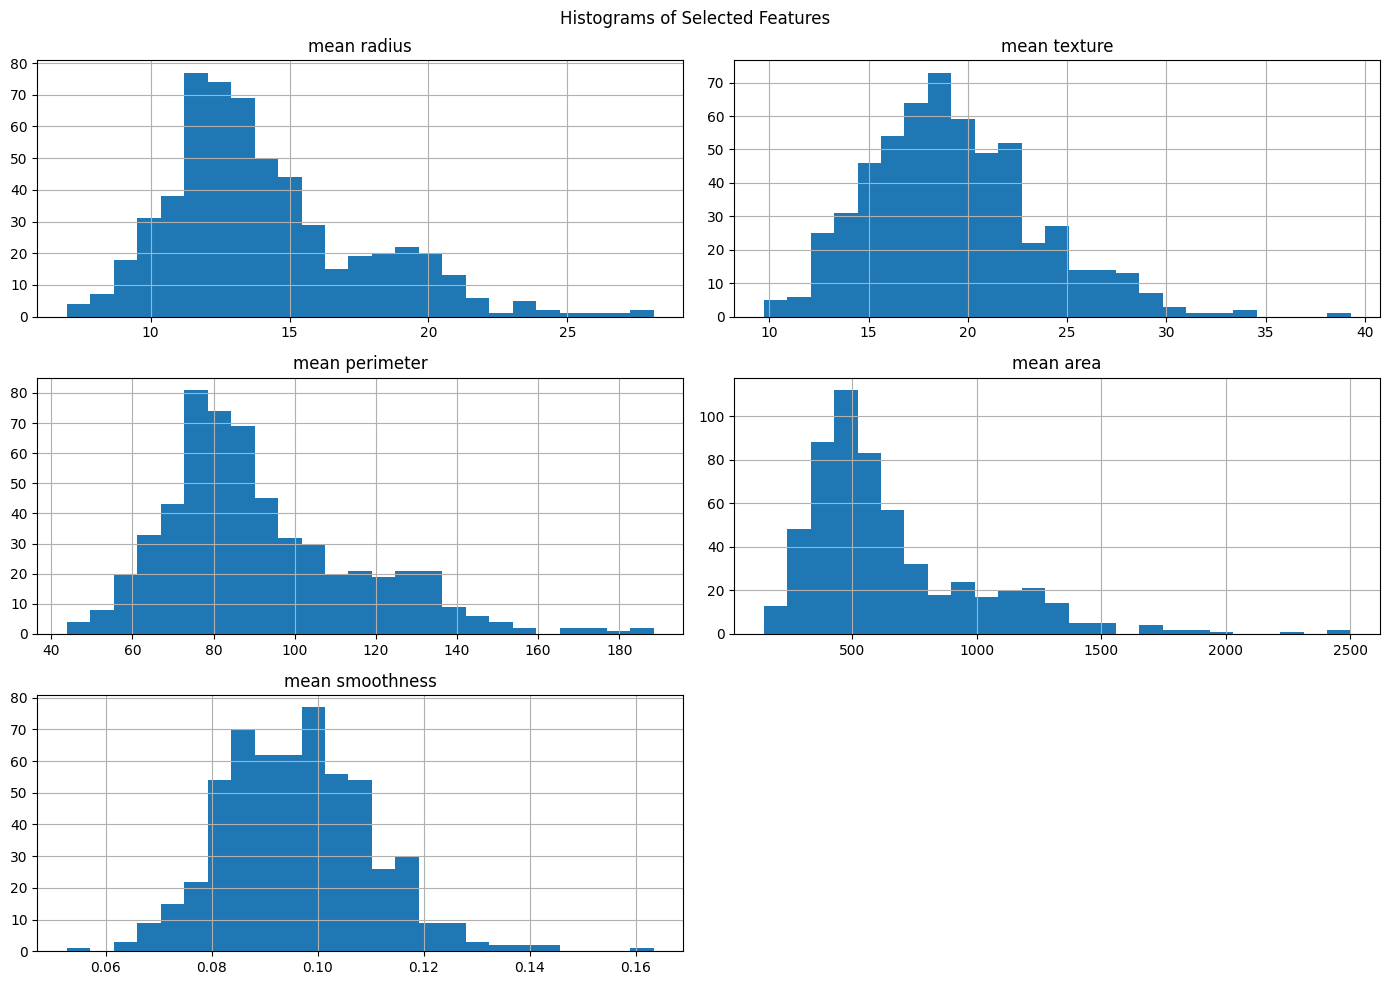

In [9]:
X[selected_features].hist(
    figsize=(14, 10),
    bins=25
)

plt.suptitle("Histograms of Selected Features")
plt.tight_layout()
plt.show()

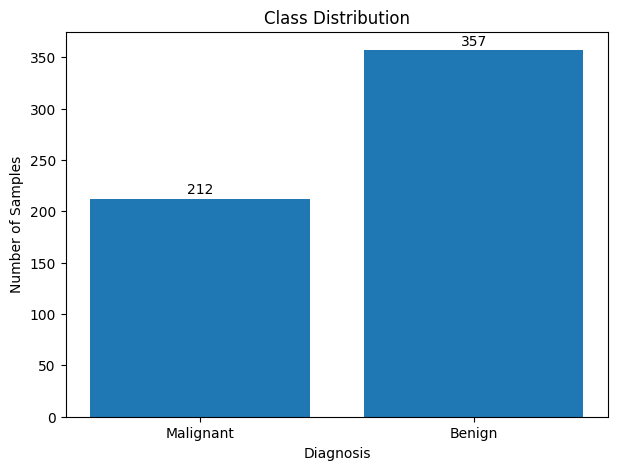

Class Distribution:
Malignant    212
Benign       357
dtype: int64


In [10]:
class_counts = y.value_counts().sort_index()

class_labels = ["Malignant", "Benign"]

plt.figure(figsize=(7, 5))
plt.bar(class_labels, class_counts.values)

plt.title("Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")

for i, count in enumerate(class_counts.values):
    plt.text(i, count + 5, str(count), ha="center")

plt.show()

print("Class Distribution:")
print(pd.Series(class_counts.values, index=class_labels))

In [11]:
class_percentage = y.value_counts(normalize=True).sort_index() * 100

for label, percentage in zip(class_labels, class_percentage):
    print(f"{label}: {percentage:.2f}%")

Malignant: 37.26%
Benign: 62.74%


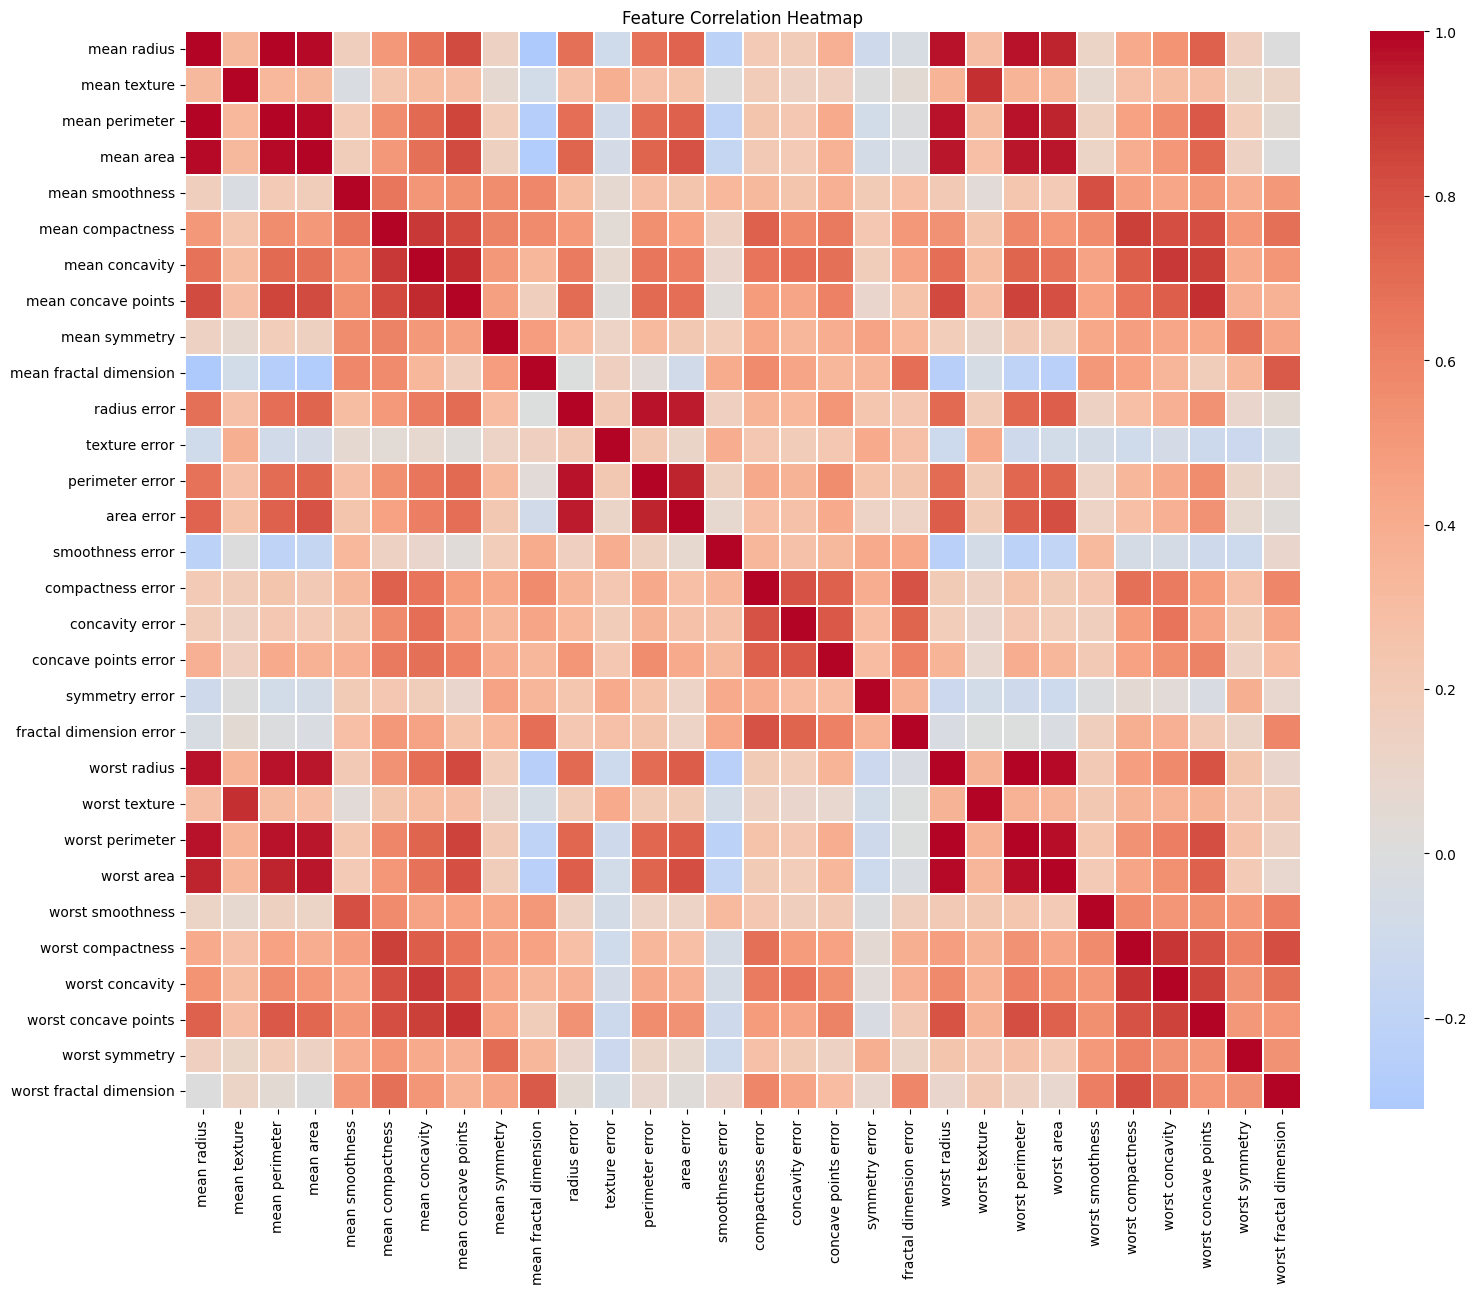

In [12]:
plt.figure(figsize=(18, 14))

correlation_matrix = X.corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title("Feature Correlation Heatmap")
plt.show()


In [13]:
# Target encoding
y_binary = y.astype(int)

print("Target Encoding:")
print("0 =", data.target_names[0])
print("1 =", data.target_names[1])

print("\nEncoded target values:")
print(y_binary.value_counts().sort_index())

Target Encoding:
0 = malignant
1 = benign

Encoded target values:
Outcome
0    212
1    357
Name: count, dtype: int64


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_binary,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 455
Testing samples: 114

Training class distribution:
Outcome
1    285
0    170
Name: count, dtype: int64

Testing class distribution:
Outcome
1    72
0    42
Name: count, dtype: int64


In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Original mean of first feature:", X_train.iloc[:, 0].mean())
print("Scaled mean of first feature:", X_train_scaled[:, 0].mean())

print("\nOriginal standard deviation:",
      X_train.iloc[:, 0].std())

print("Scaled standard deviation:",
      X_train_scaled[:, 0].std())

Original mean of first feature: 14.067213186813188
Scaled mean of first feature: -4.337433952909183e-15

Original standard deviation: 3.499379711025979
Scaled standard deviation: 1.0


In [16]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [17]:
y_pred = logistic_model.predict(X_test_scaled)

# Probability of positive class (Benign = 1)
y_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Predicted classes:")
print(y_pred)

print("\nPredicted probabilities:")
print(y_prob[:10])

Predicted classes:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]

Predicted probabilities:
[5.88824186e-08 9.99988665e-01 6.41082462e-03 5.33508537e-01
 6.52500097e-10 9.92160398e-01 9.99982825e-01 5.63527494e-07
 5.43163692e-05 8.04184941e-11]


In [18]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 0.9825
Accuracy: 98.25%


In [20]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Precision: 0.9861
Recall:    0.9861
F1 Score:  0.9861


In [21]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Malignant", "Benign"]
    )
)

Classification Report:

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



Confusion Matrix:
[[41  1]
 [ 1 71]]


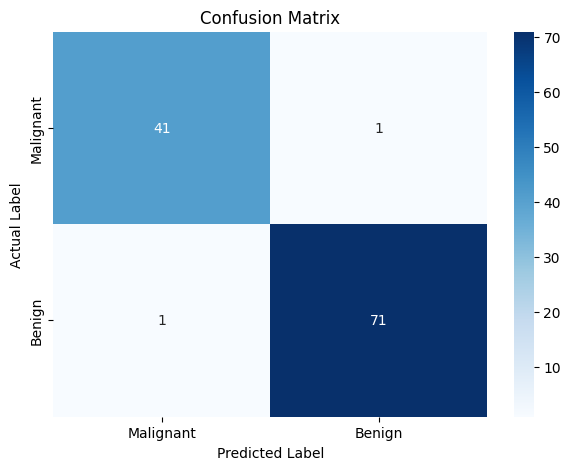

In [23]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

ROC-AUC Score: 0.9954


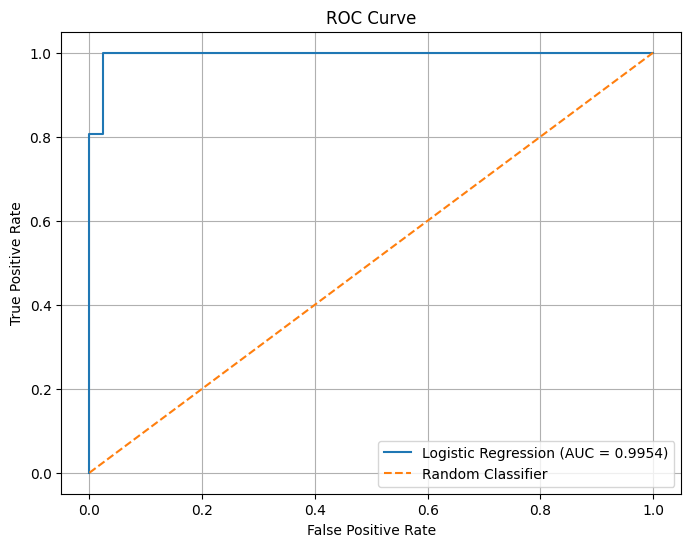

In [24]:
# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
auc_score = roc_auc_score(y_test, y_prob)

print(f"ROC-AUC Score: {auc_score:.4f}")

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_score:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

In [25]:
# Examine feature importance using logistic regression coefficients

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})

coefficients["Absolute_Coefficient"] = coefficients["Coefficient"].abs()

coefficients = coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

coefficients.head(15)

,Feature,Coefficient,Absolute_Coefficient
21,worst texture,-1.255088,1.255088
10,radius error,-1.082965,1.082965
27,worst concave points,-0.953686,0.953686
23,worst area,-0.947756,0.947756
20,worst radius,-0.947616,0.947616
28,worst symmetry,-0.939181,0.939181
13,area error,-0.929104,0.929104
26,worst concavity,-0.823151,0.823151
22,worst perimeter,-0.763220,0.763220
24,worst smoothness,-0.746625,0.746625


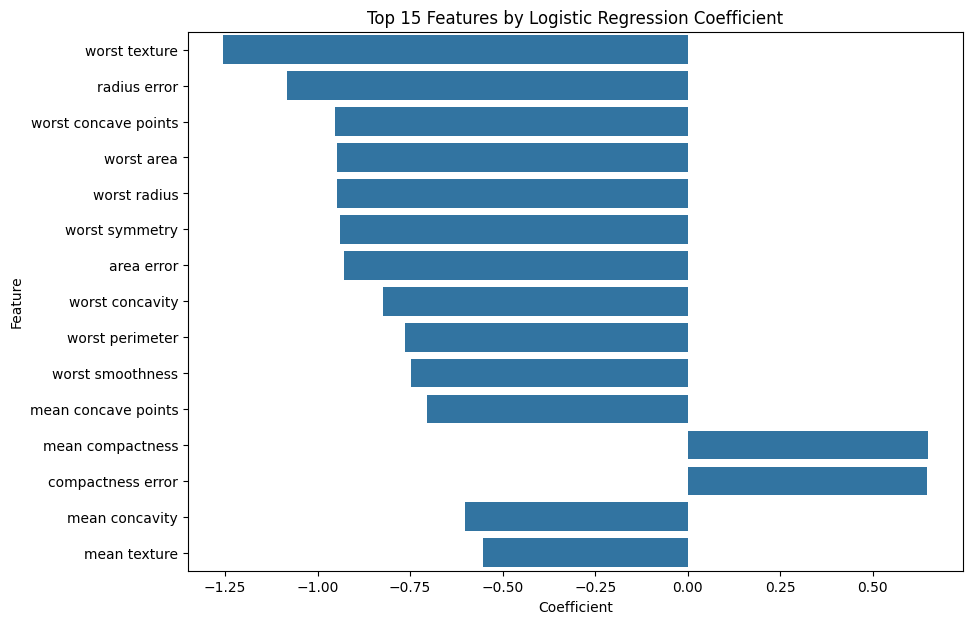

In [26]:
top_features = coefficients.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature"
)

plt.title("Top 15 Features by Logistic Regression Coefficient")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.show()

In [27]:
evaluation = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        auc_score
    ]
})

evaluation

,Metric,Score
0,Accuracy,0.982456
1,Precision,0.986111
2,Recall,0.986111
3,F1 Score,0.986111
4,ROC-AUC,0.995370


In [28]:
print("""
MODEL INTERPRETATION

1. Accuracy:
   Accuracy represents the percentage of test samples classified correctly.

2. Precision:
   Precision indicates how many samples predicted as the positive class
   were actually positive.

3. Recall:
   Recall indicates how many actual positive samples were correctly detected.

4. F1 Score:
   F1 score provides a balance between precision and recall.

5. Confusion Matrix:
   The confusion matrix shows the number of correctly and incorrectly
   classified Malignant and Benign cases.

6. ROC-AUC:
   AUC measures the model's ability to distinguish between the two classes.
   A higher AUC indicates better class separation.

7. Medical Diagnosis:
   In a medical diagnosis application, recall is particularly important
   because incorrectly classifying a malignant case as benign can have
   serious consequences. Therefore, the confusion matrix and class-wise
   recall should be examined along with accuracy.

8. Feature Interpretation:
   Logistic regression coefficients indicate the direction and relative
   strength of association between standardized features and the predicted
   class. Larger absolute coefficients have greater influence on the model.
""")


MODEL INTERPRETATION

1. Accuracy:
   Accuracy represents the percentage of test samples classified correctly.

2. Precision:
   Precision indicates how many samples predicted as the positive class
   were actually positive.

3. Recall:
   Recall indicates how many actual positive samples were correctly detected.

4. F1 Score:
   F1 score provides a balance between precision and recall.

5. Confusion Matrix:
   The confusion matrix shows the number of correctly and incorrectly
   classified Malignant and Benign cases.

6. ROC-AUC:
   AUC measures the model's ability to distinguish between the two classes.
   A higher AUC indicates better class separation.

7. Medical Diagnosis:
   In a medical diagnosis application, recall is particularly important
   because incorrectly classifying a malignant case as benign can have
   serious consequences. Therefore, the confusion matrix and class-wise
   recall should be examined along with accuracy.

8. Feature Interpretation:
   Logistic regress

In [29]:
print("=" * 50)
print("BREAST CANCER LOGISTIC REGRESSION RESULTS")
print("=" * 50)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {auc_score:.4f}")

print("\nClass-wise Performance:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Malignant", "Benign"]
    )
)

print("=" * 50)

BREAST CANCER LOGISTIC REGRESSION RESULTS
Accuracy  : 0.9825
Precision : 0.9861
Recall    : 0.9861
F1 Score  : 0.9861
ROC-AUC   : 0.9954

Class-wise Performance:
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

